In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = (4 * X.ravel() + 3 + np.random.randn(100) * 0.5)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
sgd_model = SGDRegressor(
    loss="squared_error",
    learning_rate="constant",
    eta0=0.01,
    max_iter=1000,
    tol=None,
    random_state=42
)

sgd_model.fit(X_scaled, y)

print("Coefficient:", sgd_model.coef_)
print("Intercept:", sgd_model.intercept_)
print("MSE:", mean_squared_error(y, sgd_model.predict(X_scaled)))

Coefficient: [2.29504393]
Intercept: [6.76060117]
MSE: 0.20167020317480205


In [7]:
mini_model = SGDRegressor(
    loss="squared_error",
    learning_rate="constant",
    eta0=0.01,
    random_state=42
)

batch_size = 10
epochs = 100

for epoch in range(epochs):
    indices = np.random.permutation(len(X_scaled))

    for start in range(0, len(X_scaled), batch_size):
        batch_indices = indices[start:start + batch_size]

        mini_model.partial_fit(
            X_scaled[batch_indices],
            y[batch_indices]
        )

print("Coefficient:", mini_model.coef_)
print("Intercept:", mini_model.intercept_)
print("MSE:", mean_squared_error(y, mini_model.predict(X_scaled)))

Coefficient: [2.28234672]
Intercept: [6.76033861]
MSE: 0.20195597848293165


Slope: 3.716206889251152
Intercept: 3.18818349539291
Final MSE: 0.21875267964350603


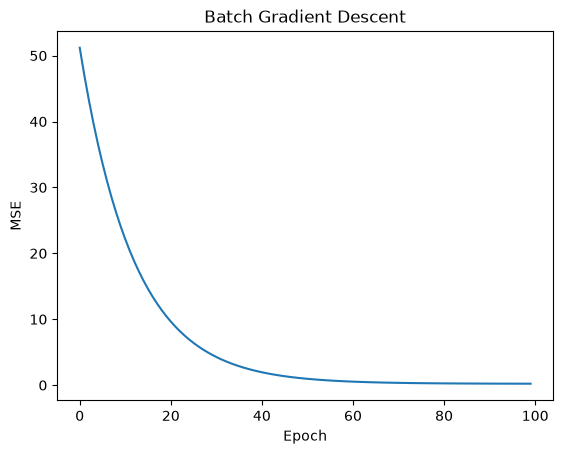

In [ ]:

X = np.asarray(X).reshape(-1, 1)
y = np.asarray(y).reshape(-1, 1)

m = 0.0
c = 0.0

learning_rate = 0.01
epochs = 100
n = len(X)

losses = []

for epoch in range(epochs):
    y_pred = m * X + c
    error = y - y_pred
    loss = np.mean(error ** 2)
    dm = (-2 / n) * np.sum(X * error)
    dc = (-2 / n) * np.sum(error)
    m = m - learning_rate * dm
    c = c - learning_rate * dc
    losses.append(loss)

print("Slope:", m)
print("Intercept:", c)
print("Final MSE:", losses[-1])

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Batch Gradient Descent")
plt.show()